# 05 · Uplift modelling (CausalML) on a SIMULATED experiment
**The dataset has no real retention-offer data.** Treatment assignment and treated outcomes are simulated; control outcomes are the real retention labels. Results are not experimentally validated causal evidence.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from src import config
pd.set_option('display.width', 160); sns.set_theme(style='whitegrid')
import json
from src import uplift_model as um
df = pd.read_csv(config.DATA_PROCESSED / 'customers_processed.csv')   # cleaned + engineered (written by ingestion)
p0 = pd.read_csv(config.DATA_PROCESSED / 'churn_scores.csv').set_index('customer_id').loc[df.customer_id, 'churn_probability'].values
print(json.dumps(um.SIM_ASSUMPTIONS, indent=2))

{
  "treatment_assignment": "Bernoulli(0.5) independent of covariates (a randomized A/B test), seed 42",
  "control_outcome": "REAL observed retention (1 - churn)",
  "treatment_effect_for_would_be_churners": "P(saved | would churn, treated at 10% discount) = tau(x), additive rules below, clipped to [0, 0.45]",
  "tau_rules": {
    "base": 0.05,
    "monthly_charges>=70": 0.18,
    "30<=monthly_charges<70": 0.08,
    "month_to_month": 0.1,
    "tenure<=12": 0.08,
    "paperless_billing": 0.05,
    "auto_pay": -0.05,
    "protection_bundle": -0.06
  },
  "sleeping_dogs": "Treated non-churners with contract>=12m and tenure>24m churn with prob 0.04 (offer prompts plan review)",
  "discount_depth": "effects calibrated to a 10% discount; other depths use a diminishing-returns multiplier (src/roi.py)"
}


In [2]:
out = um.run_uplift(df, p0, save=False); s = out['summary']; t = out['table']
print({k: s[k] for k in ['n_treated','n_control','retention_treated','retention_control','simulated_average_treatment_effect','selected_learner','share_positive_uplift']})
display(pd.DataFrame(s['evaluation_holdout']).round(3))

{'n_treated': 3471, 'n_control': 3572, 'retention_treated': 0.8176318063958513, 'retention_control': 0.7337625979843225, 'simulated_average_treatment_effect': 0.08386920841152878, 'selected_learner': 'S_learner', 'share_positive_uplift': 0.7512423683089593}


,qini,auuc,spearman_vs_reference_effect
S_learner,0.285,0.795,0.917
T_learner,0.184,0.696,0.771
Churn_risk_baseline,0.282,0.787,0.969
Random,0.052,0.550,-0.008


In [3]:
display(pd.DataFrame(s['uplift_deciles_holdout_selected']).round(3)); display(t.quadrant.value_counts())

,decile,n,mean_predicted_ite,retention_treated,retention_control,observed_uplift
0,1,212,0.264,0.620,0.375,0.245
1,2,211,0.211,0.606,0.382,0.223
2,3,211,0.144,0.667,0.537,0.130
3,4,211,0.082,0.800,0.681,0.119
4,5,212,0.035,0.866,0.810,0.056
5,6,211,0.012,0.879,0.786,0.093
6,7,211,0.002,0.967,0.916,0.051
7,8,211,-0.000,0.927,0.970,-0.043
8,9,211,-0.003,0.956,0.969,-0.013
9,10,212,-0.014,0.876,0.950,-0.073


quadrant
Persuadable     3557
Sure thing      3337
Sleeping dog     149
Name: count, dtype: int64

Text(0.5, 1.0, 'Qini curves (hold-out, simulated experiment)')

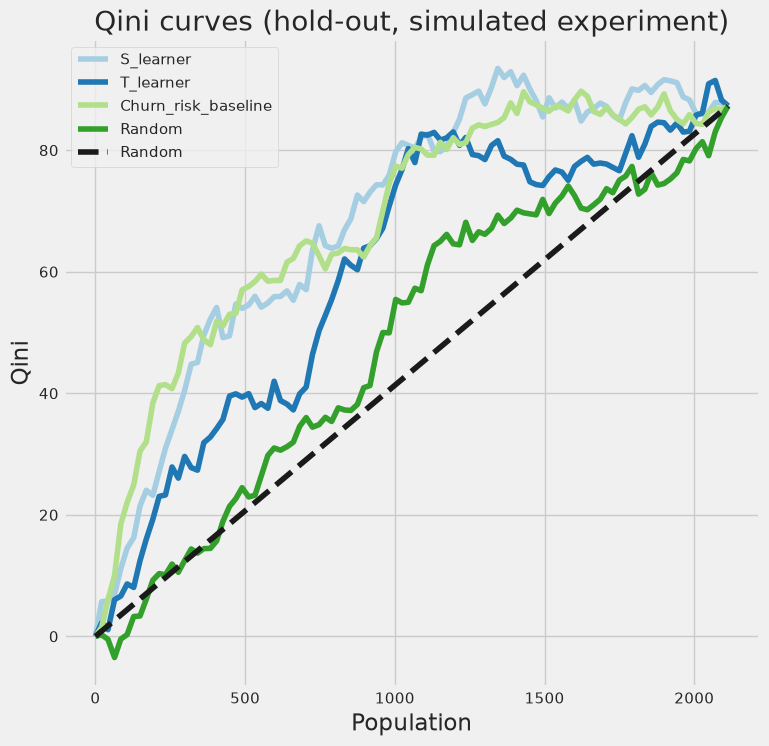

In [4]:
from causalml.metrics import plot_qini
h = pd.DataFrame(out['holdout_curves'])
plot_qini(h, outcome_col='y', treatment_col='w'); plt.title('Qini curves (hold-out, simulated experiment)')

## Likely to churn ≠ likely to respond ≠ worth the money

In [5]:
u = um.add_economics(t, df, p0)
hi = p0 >= 0.5
print('high risk:', hi.sum(), '| positive uplift:', int(u.positive_uplift.sum()), '| worthwhile at default offer:', int(u.economically_worthwhile.sum()))
print('high-risk but NOT worthwhile:', int((hi & ~u.economically_worthwhile.values).sum()))

high risk: 1648 | positive uplift: 5291 | worthwhile at default offer: 1224
high-risk but NOT worthwhile: 432


In this simulation, ranking by churn risk performs about as well as the uplift learners (see Qini above) because only would-be churners can be saved by construction. Uplift modelling adds value when real treatment effects and baseline risk diverge (e.g., sleeping dogs).